<a href="https://colab.research.google.com/github/vamsi-krishna09/Machine_Learning_Projects/blob/main/Credit_card_default.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo


In [ ]:
from ucimlrepo import fetch_ucirepo
credit_card_clients=fetch_ucirepo(id=350)
X=credit_card_clients.data.features
Y=credit_card_clients.data.targets

In [ ]:
import pandas as pd
df=pd.concat([X,Y],axis=1)
df.head(3)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [ ]:
df.shape

(30000, 24)

In [ ]:
df.columns=['LIMIT_BAL',"SEX","EDUCATION","MARRIAGE","AGE","PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6","BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6","PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6","DEFAULT"]

In [ ]:
for col in df.columns:
  print(col,"->",df[col].nunique())

LIMIT_BAL -> 81
SEX -> 2
EDUCATION -> 7
MARRIAGE -> 4
AGE -> 56
PAY_0 -> 11
PAY_2 -> 11
PAY_3 -> 11
PAY_4 -> 11
PAY_5 -> 10
PAY_6 -> 10
BILL_AMT1 -> 22723
BILL_AMT2 -> 22346
BILL_AMT3 -> 22026
BILL_AMT4 -> 21548
BILL_AMT5 -> 21010
BILL_AMT6 -> 20604
PAY_AMT1 -> 7943
PAY_AMT2 -> 7899
PAY_AMT3 -> 7518
PAY_AMT4 -> 6937
PAY_AMT5 -> 6897
PAY_AMT6 -> 6939
DEFAULT -> 2


In [ ]:
df.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [ ]:
print(credit_card_clients.metadata)
print(credit_card_clients.variables)

{'uci_id': 350, 'name': 'Default of Credit Card Clients', 'repository_url': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients', 'data_url': 'https://archive.ics.uci.edu/static/public/350/data.csv', 'abstract': "This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods.", 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 30000, 'num_features': 23, 'feature_types': ['Integer', 'Real'], 'demographics': ['Sex', 'Education Level', 'Marital Status', 'Age'], 'target_col': ['Y'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C55S3H', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 365, 'type': 'NATIVE', 'title': 'The comparisons of data mining techniques for the predictive accuracy of 

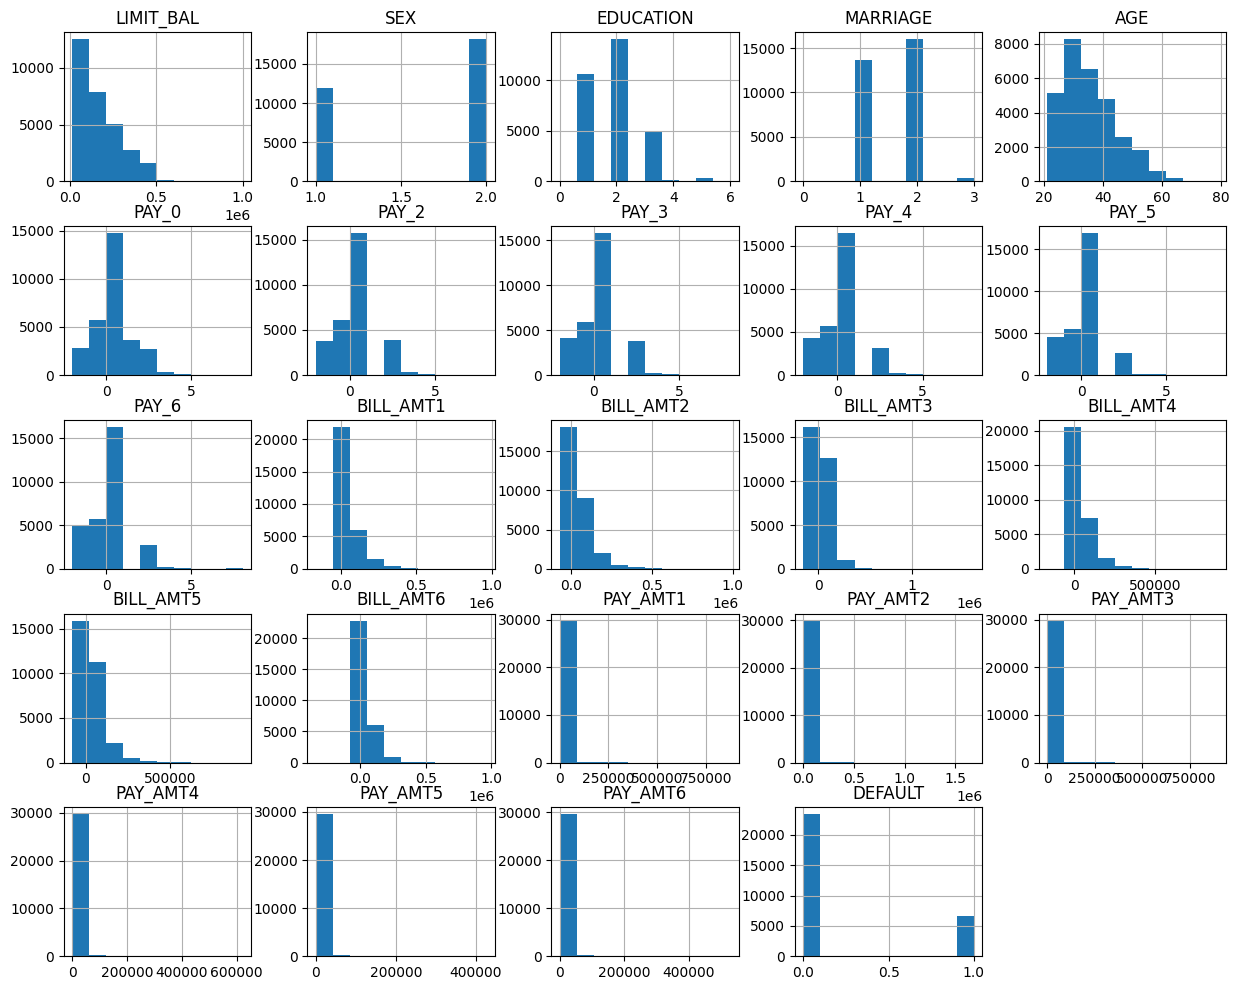

In [ ]:
import matplotlib.pyplot as plt
df.hist(figsize=(15,12))
plt.show()

In [ ]:
df["EDUCATION"]=df["EDUCATION"].replace({0:4,5:4,6:4})
df['EDUCATION'].value_counts()

,count
EDUCATION,
2,14030
1,10585
3,4917
4,468


In [ ]:
from sklearn.model_selection import train_test_split
x=df.drop(columns=['DEFAULT'])
y=df['DEFAULT']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)


In [ ]:
numeric_cols=['LIMIT_BAL','AGE',"BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6","PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]
x_train=x_train.copy()
x_test=x_test.copy()

In [ ]:
for col in numeric_cols:
  Q1,Q3=x_train[col].quantile(0.25),x_train[col].quantile(0.75)
  IQR=Q3-Q1
  lower,upper=Q1-1.5*IQR,Q3+1.5*IQR
  x_train[col]=x_train[col].clip(lower,upper)
  x_test[col]=x_test[col].clip(lower,upper)
print("Outliers done")

Outliers done


In [ ]:
pay_cols=['PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']
for split_df in [x_train,x_test]:
  split_df['avg_pay_delay']=split_df[pay_cols].mean(axis=1)
  split_df['max_pay_delay']=split_df[pay_cols].max(axis=1)
  split_df['pay_trend']=split_df['PAY_0']-split_df['PAY_6']
  epsilon=1e-6
  x_train['pay_ratio_1']=x_train['PAY_AMT1']/(x_train['BILL_AMT1'].abs()+epsilon)
  x_test['pay_ratio_1']=x_test['PAY_AMT1']/(x_test['BILL_AMT1'].abs()+epsilon)
  split_df['pay_ratio_avg']=(split_df[['PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']].sum(axis=1))/(split_df[['BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6']].sum(axis=1)+1)




In [ ]:
import numpy as np
money_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
              'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

for split_df in [x_train, x_test]:
    for col in money_cols:
        split_df[col] = np.sign(split_df[col]) * np.log1p(np.abs(split_df[col]))

In [ ]:
train_with_target = x_train.copy()
train_with_target['DEFAULT'] = y_train
print(train_with_target.corr()['DEFAULT'].abs().sort_values(ascending=False))

DEFAULT          1.000000
max_pay_delay    0.335716
PAY_0            0.327671
avg_pay_delay    0.284988
PAY_2            0.265527
PAY_3            0.238930
PAY_4            0.220063
PAY_5            0.203260
PAY_6            0.188717
PAY_AMT1         0.166740
LIMIT_BAL        0.162115
PAY_AMT2         0.144859
PAY_AMT3         0.137310
pay_trend        0.130634
PAY_AMT4         0.118884
PAY_AMT6         0.109672
PAY_AMT5         0.105612
SEX              0.043862
EDUCATION        0.031975
MARRIAGE         0.019661
BILL_AMT1        0.017008
AGE              0.012519
pay_ratio_1      0.010107
BILL_AMT5        0.009157
pay_ratio_avg    0.006685
BILL_AMT3        0.006060
BILL_AMT2        0.005601
BILL_AMT4        0.005498
BILL_AMT6        0.002112
Name: DEFAULT, dtype: float64


In [ ]:
import numpy as np
inf_check=x_train.isin([np.inf,-np.inf]).sum()
print(inf_check)

LIMIT_BAL        0
SEX              0
EDUCATION        0
MARRIAGE         0
AGE              0
PAY_0            0
PAY_2            0
PAY_3            0
PAY_4            0
PAY_5            0
PAY_6            0
BILL_AMT1        0
BILL_AMT2        0
BILL_AMT3        0
BILL_AMT4        0
BILL_AMT5        0
BILL_AMT6        0
PAY_AMT1         0
PAY_AMT2         0
PAY_AMT3         0
PAY_AMT4         0
PAY_AMT5         0
PAY_AMT6         0
avg_pay_delay    0
max_pay_delay    0
pay_trend        0
pay_ratio_1      0
pay_ratio_avg    0
dtype: int64


In [ ]:
print("x_train columns:", x_train.columns.tolist())
print("x_test columns:", x_test.columns.tolist())
print("Same columns, same order:", list(x_train.columns) == list(x_test.columns))

# show the actual difference
print("In x_train but not x_test:", set(x_train.columns) - set(x_test.columns))
print("In x_test but not x_train:", set(x_test.columns) - set(x_train.columns))

x_train columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'avg_pay_delay', 'max_pay_delay', 'pay_trend', 'pay_ratio_1', 'pay_ratio_avg']
x_test columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'pay_ratio_1', 'avg_pay_delay', 'max_pay_delay', 'pay_trend', 'pay_ratio_avg']
Same columns, same order: False
In x_train but not x_test: set()
In x_test but not x_train: set()


In [ ]:
x_test = x_test[x_train.columns]

# now re-run scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, recall_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(x_train, y_train)
dummy_preds = dummy.predict(x_test)

print("Baseline F1:", f1_score(y_test, dummy_preds))
print("Baseline Recall:", recall_score(y_test, dummy_preds))


Baseline F1: 0.0
Baseline Recall: 0.0


In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(x_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, class_weight='balanced', random_state=42
)
rf.fit(x_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=300,
                       random_state=42)

In [ ]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42
)
xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

models = {
    "Logistic Regression": (lr, x_test_scaled),
    "Random Forest": (rf, x_test),
    "XGBoost": (xgb, x_test)
}

results = []
for name, (model, X_te) in models.items():
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]
    results.append({
        "Model": name,
        "F1 Score": round(f1_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4)
    })
    print(f"\n--- {name} ---")
    print(classification_report(y_test, preds))

results_df = pd.DataFrame(results)
print(results_df)


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.88      0.76      0.81      4673
           1       0.42      0.62      0.50      1327

    accuracy                           0.73      6000
   macro avg       0.65      0.69      0.66      6000
weighted avg       0.78      0.73      0.75      6000


--- Random Forest ---
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4673
           1       0.52      0.55      0.54      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.70      0.70      6000
weighted avg       0.79      0.79      0.79      6000


--- XGBoost ---
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      4673
           1       0.48      0.58      0.52      1327

    accuracy                           0.77      6000
   macro avg       0.67      0.70      0.68      6000
weigh

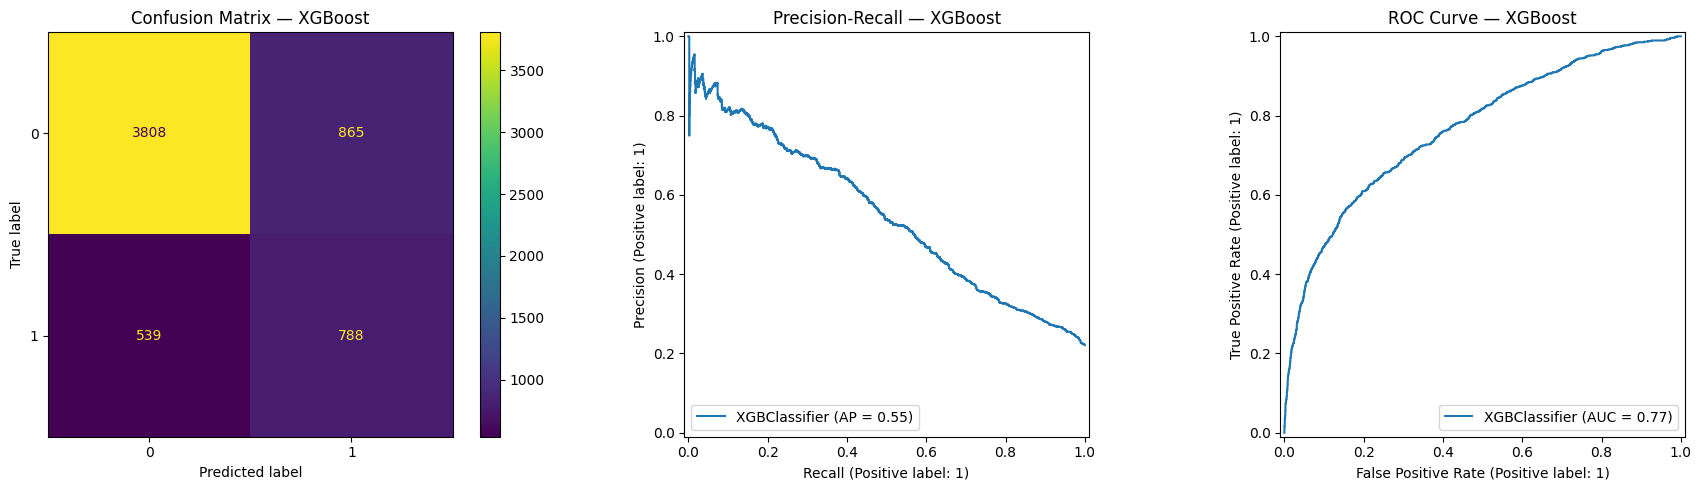

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_estimator(xgb, x_test, y_test, ax=axes[0])
axes[0].set_title("Confusion Matrix — XGBoost")

PrecisionRecallDisplay.from_estimator(xgb, x_test, y_test, ax=axes[1])
axes[1].set_title("Precision-Recall — XGBoost")

RocCurveDisplay.from_estimator(xgb, x_test, y_test, ax=axes[2])
axes[2].set_title("ROC Curve — XGBoost")

plt.tight_layout()
plt.show()

In [ ]:
for group in sorted(x_test['SEX'].unique()):
    mask = x_test['SEX'] == group
    group_preds = xgb.predict(x_test[mask])
    print(f"SEX={group}: F1={f1_score(y_test[mask], group_preds):.3f}, "
          f"Recall={recall_score(y_test[mask], group_preds):.3f}, n={mask.sum()}")


SEX=1: F1=0.516, Recall=0.586, n=2402
SEX=2: F1=0.538, Recall=0.599, n=3598


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    verbose=1,
    n_jobs=-1
)
grid_search.fit(x_train, y_train)
print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

best_xgb = grid_search.best_estimator_

final_preds = best_xgb.predict(x_test)
print("\n--- Tuned XGBoost — Final Test Performance ---")
print(classification_report(y_test, final_preds))


Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}
Best CV F1: 0.541392598672472

--- Tuned XGBoost — Final Test Performance ---
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      4673
           1       0.47      0.62      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000



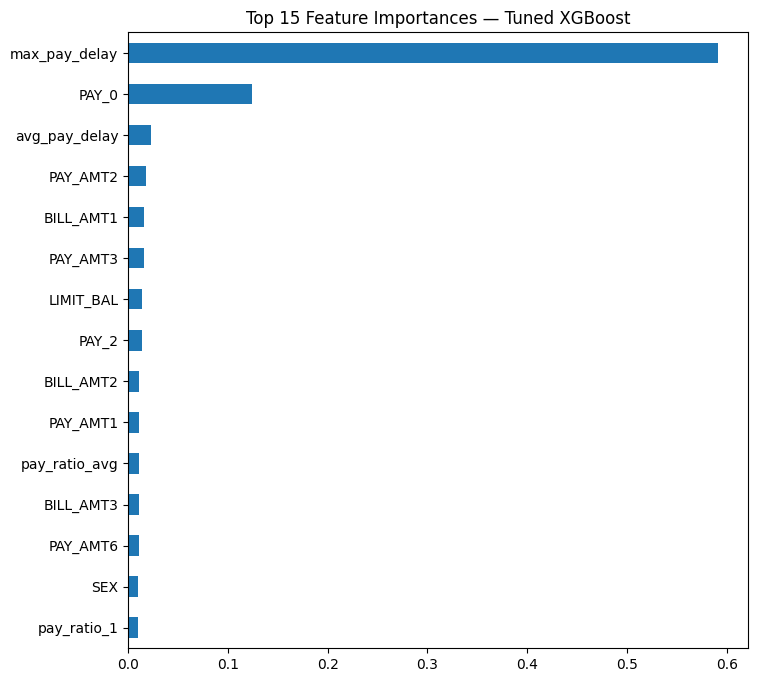

In [ ]:
importances = pd.Series(best_xgb.feature_importances_, index=x_train.columns).sort_values(ascending=False)
importances.head(15).plot(kind='barh', figsize=(8, 8))
plt.title("Top 15 Feature Importances — Tuned XGBoost")
plt.gca().invert_yaxis()
plt.show()

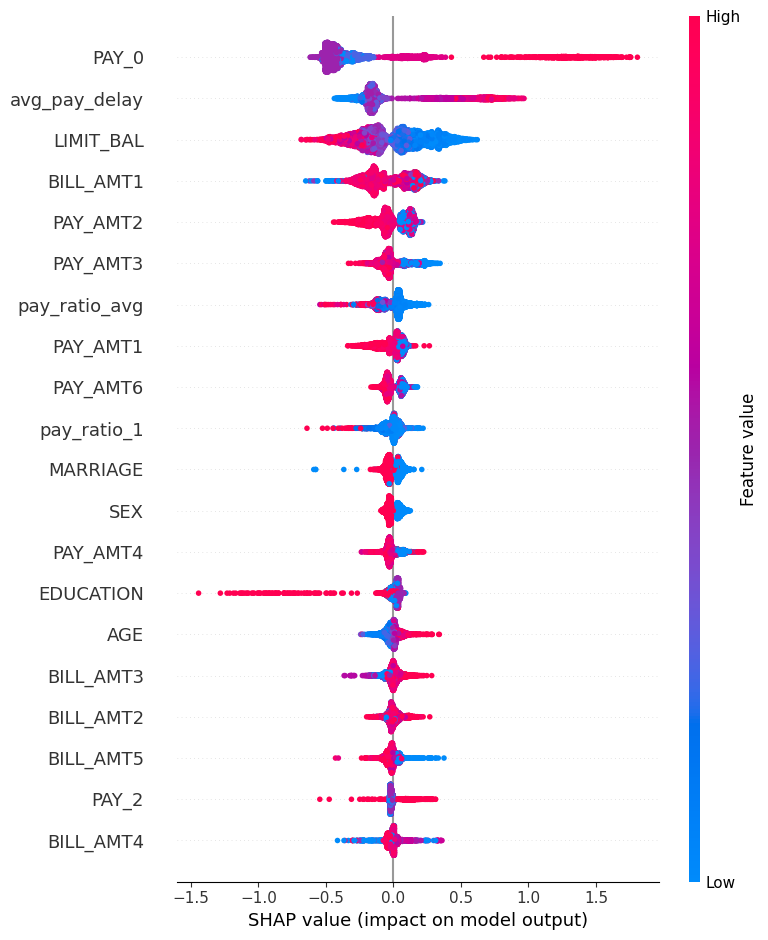

In [ ]:
import shap

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(x_test)

shap.summary_plot(shap_values, x_test)


In [ ]:
def predict_with_explanation(customer_data: pd.DataFrame):
    pred = best_xgb.predict(customer_data)[0]
    prob = best_xgb.predict_proba(customer_data)[0][1]
    shap_vals = explainer.shap_values(customer_data)
    feature_impact = pd.Series(shap_vals[0], index=customer_data.columns).sort_values(key=abs, ascending=False)
    return {
        "prediction": int(pred),
        "default_probability": round(float(prob), 4),
        "top_contributing_features": feature_impact.head(5).round(4).to_dict()
    }

sample = x_test.iloc[[0]]
print(predict_with_explanation(sample))

{'prediction': 0, 'default_probability': 0.4092, 'top_contributing_features': {'PAY_0': -0.31459999084472656, 'LIMIT_BAL': 0.22110000252723694, 'avg_pay_delay': -0.1404000073671341, 'PAY_AMT1': -0.11299999803304672, 'BILL_AMT3': -0.08829999715089798}}


In [ ]:
import joblib

joblib.dump(best_xgb, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')            # not used by xgb directly, but saved for consistency/LR reuse
joblib.dump(explainer, 'explainer.pkl')
joblib.dump(list(x_train.columns), 'feature_names.pkl')

print("Saved: model.pkl, scaler.pkl, explainer.pkl, feature_names.pkl")


Saved: model.pkl, scaler.pkl, explainer.pkl, feature_names.pkl


In [ ]:
!pip freeze > requirements.txt
print("Saved requirements.txt")

Saved requirements.txt


In [ ]:
print(x_train.columns.tolist())
print(x_test.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'avg_pay_delay', 'pay_trend', 'pay_ratio_1', 'pay_ratio_avg']
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'avg_pay_delay', 'pay_trend', 'pay_ratio_1', 'pay_ratio_avg']


In [ ]:
from google.colab import files
files.download('model.pkl')
files.download('explainer.pkl')
files.download('feature_names.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>